<a href="https://colab.research.google.com/github/Tejasp9090/ML_Practice/blob/main/multiLinear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [3]:
car = pd.read_csv('/content/mtcars.csv')
car[:2]

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,21.0,6,160.0,110,3.9,2.620,16.46,0,1,4,4
1,21.0,6,160.0,110,3.9,2.875,17.02,0,1,4,4


In [4]:
car.shape

(32, 11)

In [5]:
car['cyl'].value_counts()

,count
cyl,
8,14
4,11
6,7


In [6]:
# Missing Value
car.isna().sum()

,0
mpg,0
cyl,0
disp,0
hp,0
drat,0
wt,0
qsec,0
vs,0
am,0
gear,0


Here Is No Missing Value..


In [7]:
#check columns
car.columns

Index(['mpg', 'cyl', 'disp', 'hp', 'drat', 'wt', 'qsec', 'vs', 'am', 'gear',
       'carb'],
      dtype='object')

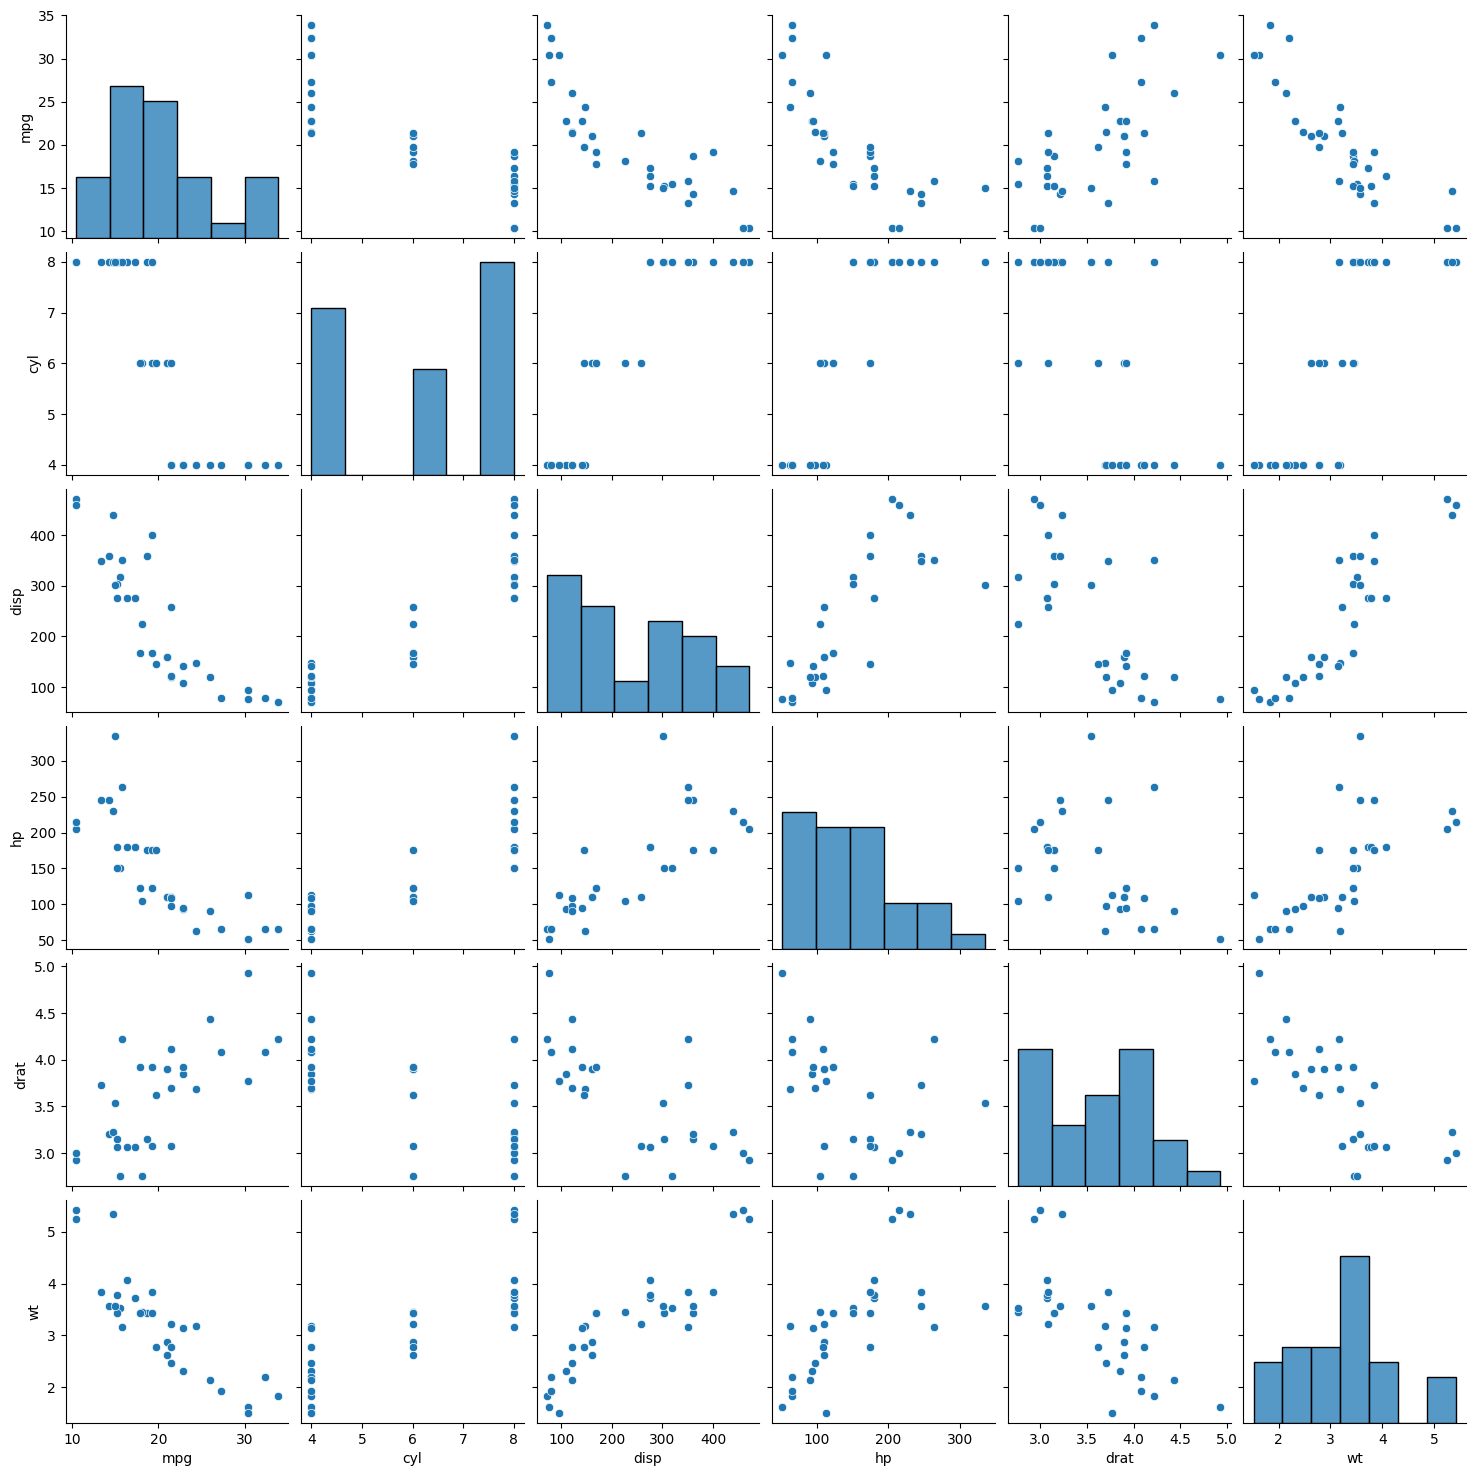

In [10]:
import seaborn as sns
sns.pairplot(data=car[['mpg', 'cyl', 'disp', 'hp', 'drat', 'wt']])

In [12]:
car.corr().style.background_gradient('Reds')

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
mpg,1.000000,-0.852162,-0.847551,-0.776168,0.681172,-0.867659,0.418684,0.664039,0.599832,0.480285,-0.550925
cyl,-0.852162,1.000000,0.902033,0.832447,-0.699938,0.782496,-0.591242,-0.810812,-0.522607,-0.492687,0.526988
disp,-0.847551,0.902033,1.000000,0.790949,-0.710214,0.887980,-0.433698,-0.710416,-0.591227,-0.555569,0.394977
hp,-0.776168,0.832447,0.790949,1.000000,-0.448759,0.658748,-0.708223,-0.723097,-0.243204,-0.125704,0.749812
drat,0.681172,-0.699938,-0.710214,-0.448759,1.000000,-0.712441,0.091205,0.440278,0.712711,0.699610,-0.090790
wt,-0.867659,0.782496,0.887980,0.658748,-0.712441,1.000000,-0.174716,-0.554916,-0.692495,-0.583287,0.427606
qsec,0.418684,-0.591242,-0.433698,-0.708223,0.091205,-0.174716,1.000000,0.744535,-0.229861,-0.212682,-0.656249
vs,0.664039,-0.810812,-0.710416,-0.723097,0.440278,-0.554916,0.744535,1.000000,0.168345,0.206023,-0.569607
am,0.599832,-0.522607,-0.591227,-0.243204,0.712711,-0.692495,-0.229861,0.168345,1.000000,0.794059,0.057534
gear,0.480285,-0.492687,-0.555569,-0.125704,0.699610,-0.583287,-0.212682,0.206023,0.794059,1.000000,0.274073


<Axes: xlabel='wt', ylabel='disp'>

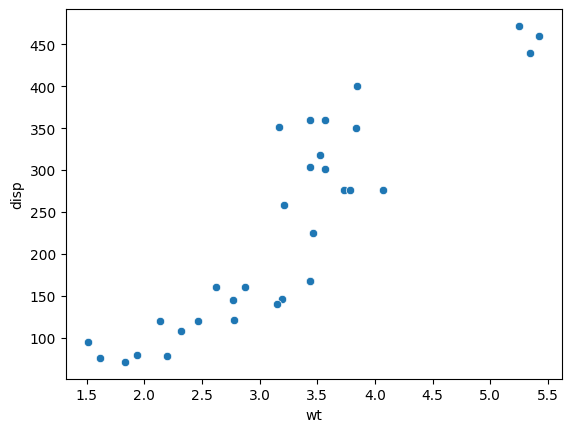

In [13]:
sns.scatterplot(data=car,x='wt',y='disp')

In [14]:
x=car[['cyl','wt','drat','vs']]

y=car['mpg']

In [15]:
# Import Aglorithm
from sklearn.linear_model import LinearRegression

In [16]:
model =LinearRegression()
model

LinearRegression()

In [17]:
model.fit(x,y)

LinearRegression()

In [45]:
# Select random 5 records for testing
test_data = x.head(5)
test_data



,cyl,wt,drat,vs
0,6,2.620,3.90,0
1,6,2.875,3.90,0
2,4,2.320,3.85,1
3,6,3.215,3.08,1
4,8,3.440,3.15,0


In [46]:
y.head().values

array([4.58257569, 4.58257569, 4.77493455, 4.6260134 , 4.32434966])

In [49]:
model.predict(test_data)

array([4.656398  , 4.55965596, 5.12198668, 4.5062401 , 4.06875785])

In [44]:

import pandas as pd
import gradio as gr
from sklearn.linear_model import LinearRegression

# Load dataset
url = "https://raw.githubusercontent.com/selva86/datasets/master/mtcars.csv"
df = pd.read_csv(url)

# Features and target
features = ["cyl", "wt", "drat", "vs"]
X = df[features]
y = df["mpg"]

# Train the model on the complete dataset
model = LinearRegression()
model.fit(X, y)

# Prediction function
def predict_mpg(cyl, wt, drat, vs):
    inputs = pd.DataFrame(
        [[cyl, wt, drat, vs]],
        columns=features
    )
    prediction = model.predict(inputs)[0]
    return round(float(prediction), 2)

# Preset values
presets = [
    [4, 2.2, 3.85, 1],
    [6, 3.2, 3.10, 0],
    [8, 4.0, 3.15, 0],
]

# Build the interface
with gr.Blocks(title="MT Cars MPG Predictor", theme=gr.themes.Soft()) as app:
    gr.Markdown(
        """
        <div style="text-align:center">
        <h1>🚗 MT Cars MPG Predictor</h1>
        <h3>Estimate vehicle fuel efficiency in Miles Per Gallon (MPG)</h3>
        </div>
        """
    )

    with gr.Row():
        with gr.Column(scale=6):
            gr.Markdown("## 🛠️ Engine & Design Specifications")

            cyl = gr.Dropdown(
                choices=[4, 6, 8],
                value=6,
                label="Cylinders (cyl)"
            )

            wt = gr.Number(
                value=3.2,
                label="Weight (wt) — 1000 lbs"
            )

            drat = gr.Number(
                value=3.5,
                label="Rear Axle Ratio (drat)"
            )

            vs = gr.Radio(
                choices=[
                    ("V-Shaped (0)", 0),
                    ("Straight (1)", 1)
                ],
                value=0,
                label="Engine Block (V/S)"
            )

            predict_btn = gr.Button(
                "✨ Calculate Predicted MPG",
                variant="primary"
            )

        with gr.Column(scale=4):
            gr.Markdown("## 📊 Prediction Result")

            output = gr.Number(
                label="Estimated Miles Per Gallon (MPG)",
                interactive=False
            )

            gr.Markdown("## 💡 Standard Car Presets")

            preset_table = gr.Dataframe(
                value=pd.DataFrame(
                    presets,
                    columns=["Cylinders (cyl)", "Weight (wt)",
                             "Rear Axle Ratio (drat)", "Engine (vs)"]
                ),
                interactive=False
            )

            preset_choice = gr.Dropdown(
                choices=["4-cylinder car", "6-cylinder car",
                         "8-cylinder car"],
                value="6-cylinder car",
                label="Choose a preset"
            )

            load_btn = gr.Button("Load Preset")

            def load_preset(choice):
                index = {
                    "4-cylinder car": 0,
                    "6-cylinder car": 1,
                    "8-cylinder car": 2
                }[choice]
                return presets[index]

            load_btn.click(
                load_preset,
                inputs=preset_choice,
                outputs=[cyl, wt, drat, vs]
            )

    predict_btn.click(
        predict_mpg,
        inputs=[cyl, wt, drat, vs],
        outputs=output
    )

app.launch(share=True)


/tmp/ipykernel_457/1930826291.py:35: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(title="MT Cars MPG Predictor", theme=gr.themes.Soft()) as app:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://91dce401cb6156081d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
